# Lab 02 — CIFAR-10: EDA và Feature Engineering

Raw → kiểm tra dữ liệu → tiền xử lý → đặc trưng thủ công. [Báo cáo](../walkthrough_lab_02.md) · [Source EDA](../src/eda.py)

Notebook đọc artifact EDA đã lưu. Thống kê pixel, đặc trưng và ảnh trung bình chỉ dùng train chưa augmentation; validation/test chỉ tham gia các kiểm tra chất lượng và phân chia được ghi rõ. Đây là khám phá dữ liệu, không phải kết quả dự đoán mô hình.

In [2]:
from pathlib import Path
import os, sys
ROOT = next(p for p in [Path(os.getenv('LAB02_ROOT', '.')).resolve(), *Path.cwd().resolve().parents] if (p / 'src/eda.py').exists())
sys.path.insert(0, str(ROOT))
from src import eda
OUT = eda.context(ROOT)
eda.overview(OUT)

,split,samples,shape,dtype,pixel_min,pixel_max,memory_mib
0,train,45000,32 x 32 x 3,uint8,0,255,131.84
1,val,5000,32 x 32 x 3,uint8,0,255,14.65
2,test,10000,32 x 32 x 3,uint8,0,255,29.30


## 1. Chất lượng ảnh raw

Kiểm tra checksum batch chính thức, nhãn, pixel hữu hạn, ảnh hằng và ảnh trùng byte trong/chéo các tập. Chỉ ghi nhận; giữ nguyên dữ liệu gốc.

In [3]:
eda.integrity_summary(OUT)

split,test,train,val
check,,,
constant_images,0,0,0
invalid_labels,0,0,0
nonfinite_pixels,0,0,0


,check,count
0,exact duplicate images across all partitions,0


## 2. Phân bố lớp và ảnh mẫu

Split stratified seed 42 được lưu một lần. Ảnh mẫu chỉ lấy từ train, kèm index gốc để truy vết.

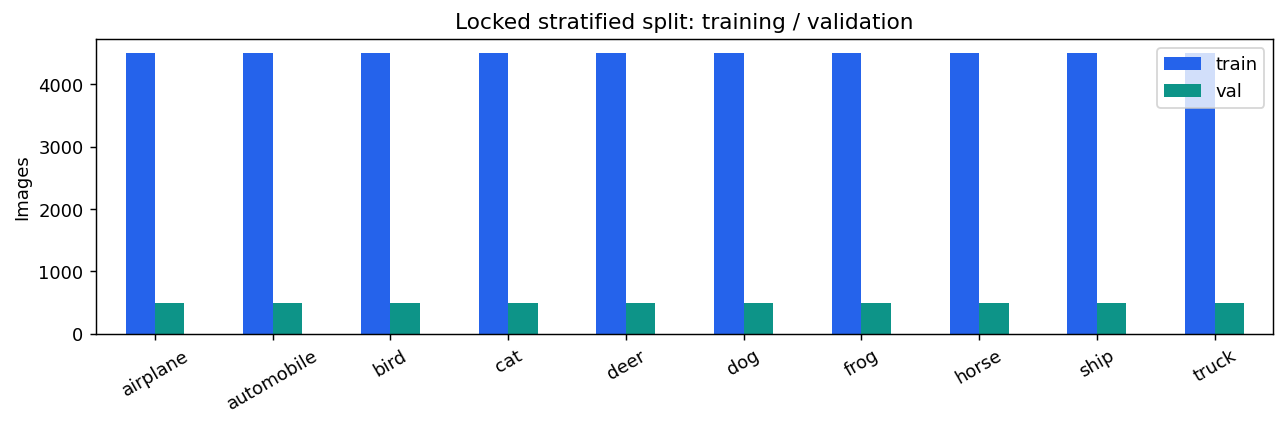

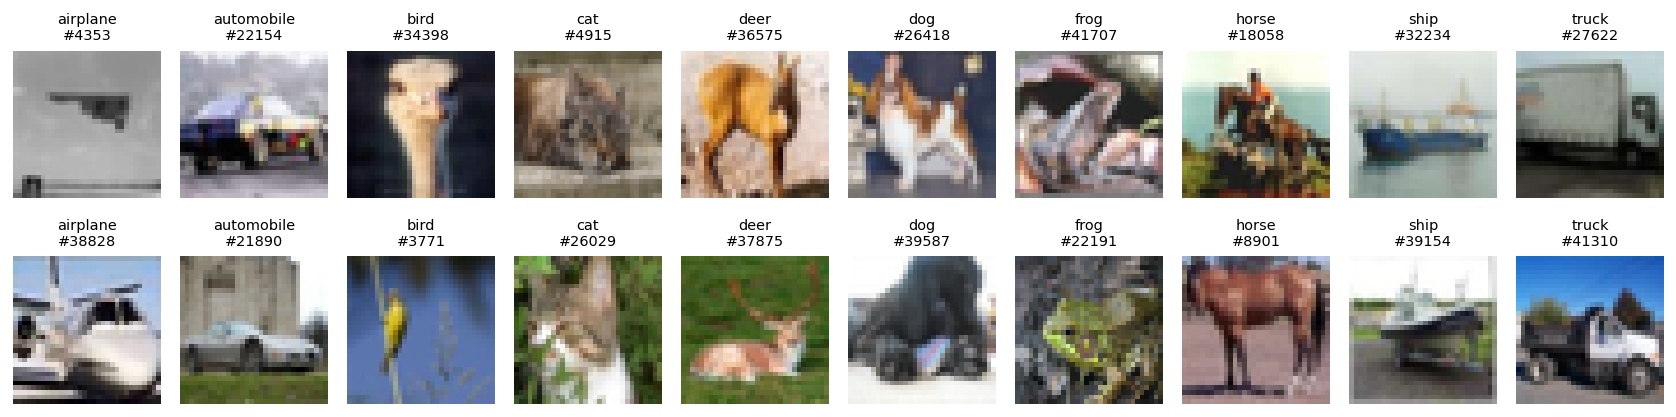

In [4]:
eda.gallery(OUT, 'class_distribution', 'sample_images')

## 3. Thống kê pixel và cấu trúc không gian

Histogram, mean/std và heatmap đo trên toàn bộ 45.000 ảnh train, không augmentation.

| Output | Cách đọc | Ý nghĩa và giới hạn |
|---|---|---|
| Histogram RGB | X: cường độ pixel /255 từ 0 đến 1; Y: tỷ lệ giá trị của từng kênh tại mỗi mức | Đường cao nghĩa là mức đó xuất hiện nhiều. Đỉnh gần 1 chưa đủ kết luận ảnh cháy sáng |
| Mean / Std | Mean là trung bình; Std là độ lệch chuẩn tổng thể của mỗi kênh | Mô tả màu và mức phân tán trên train; không tự động là bộ mean/std dùng để Normalize |
| Ảnh trung bình từng lớp | Lấy trung bình RGB tại cùng vị trí qua các ảnh train cùng lớp | Chi tiết và vị trí khác nhau bị hòa vào nhau nên ảnh mờ; không phải ảnh gốc lỗi hay dự đoán của mô hình |
| Spatial statistics | Mean brightness / pixel variance tại mỗi vị trí | Mô tả phân bố không gian; không phải bản đồ chú ý của mô hình |

Màu nền trời, nước hoặc cây cỏ có thể giải thích một số xu hướng nhưng chỉ là giả thuyết khi chưa đối chiếu ảnh gốc.

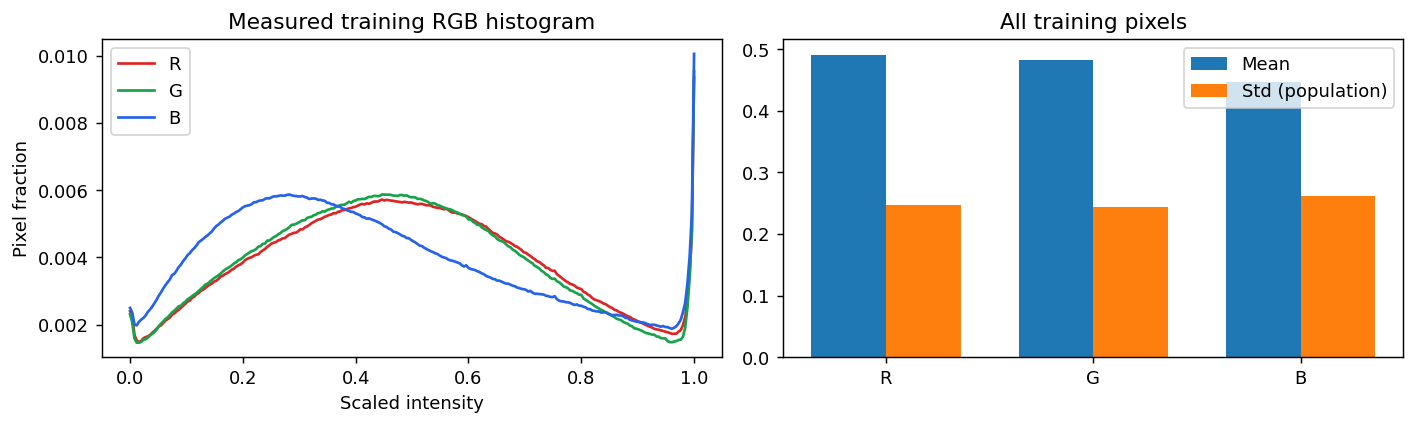

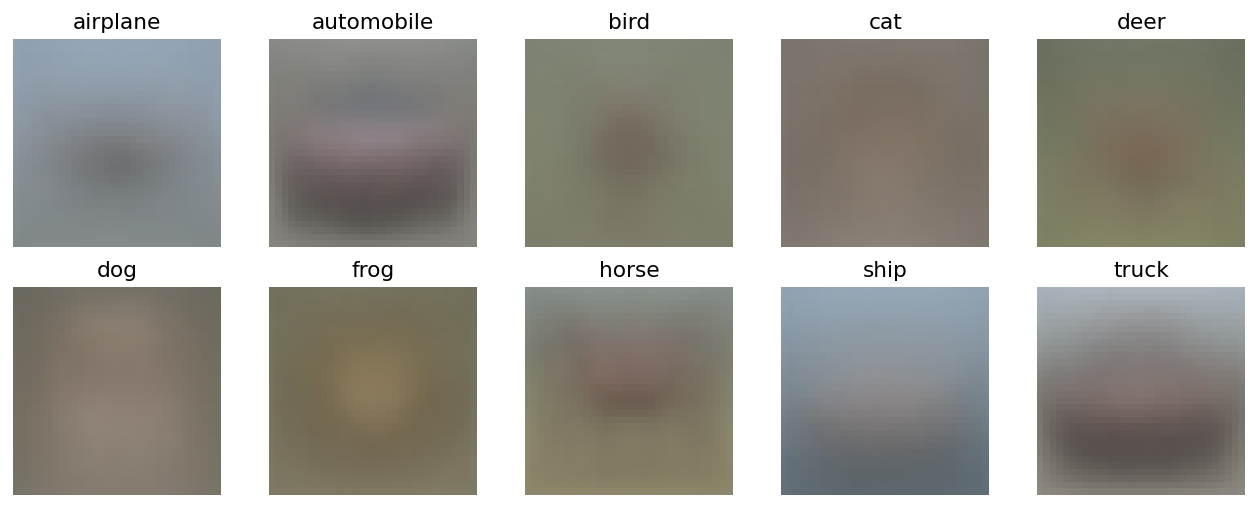

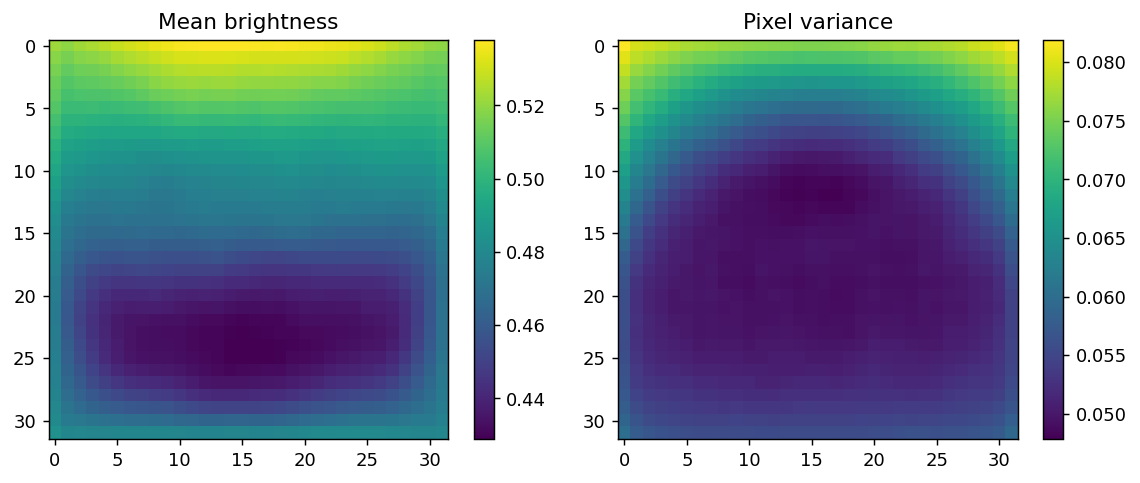

In [5]:
eda.gallery(OUT, 'pixel_statistics', 'class_mean_images', 'spatial_statistics')

## 4. Tiền xử lý

Pipeline cố định: RGB uint8 HWC `(32,32,3)` → resize 64×64 → ToTensor (chia 255, đổi sang CHW `(3,64,64)`) → Normalize.

- Resize nội suy làm ảnh mượt hơn nhưng không bổ sung chi tiết thật.
- Normalize từng kênh: `(pixel/255 − mean) / std`. Giá trị âm là bình thường; 0 nghĩa là bằng mean dùng để chuẩn hóa, +1 nghĩa là cao hơn mean một std.
- Mean/std ImageNet là hằng số của hợp đồng pretrained, khác thống kê CIFAR-10 đo ở mục 3. Không fit normalization trên validation/test.
- Histogram bên phải chỉ dùng pixel của ảnh minh họa sau chuẩn hóa, không phải toàn train. Mỗi ảnh không bắt buộc có mean 0, std 1.

### Tiền xử lý cố định và augmentation

| Giai đoạn Modeling của run đang chọn | Xử lý ảnh |
|---|---|
| Train head | Preprocessing cố định; cache đặc trưng, không augmentation |
| Train fine-tune | RandomCrop(32, padding=4, reflect) → HorizontalFlip(p=0.5) → preprocessing cố định |
| Validation / test | Chỉ preprocessing cố định, không augmentation |

EDA giữ ảnh chưa augmentation để mô tả dữ liệu gốc. Dropout, freeze và optimizer được giải thích trong [Modeling](02_lab02_modeling.ipynb), không phải bước biến đổi ảnh EDA.

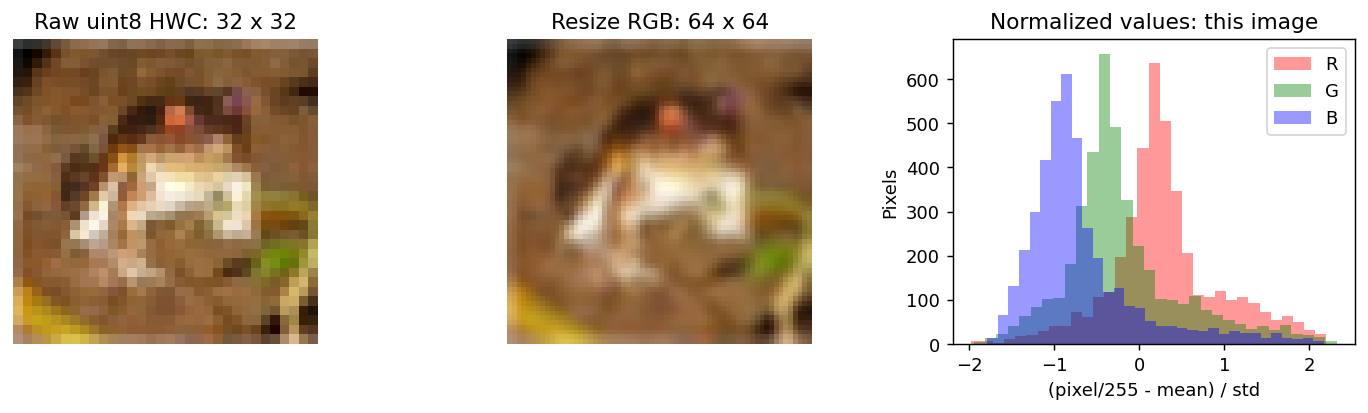

In [6]:
eda.gallery(OUT, 'preprocessing_preview')

## 5. Feature Engineering

Các đặc trưng sau mô tả ảnh train và phục vụ phân tích, không được đưa thêm vào tensor đầu vào CNN.

| Đặc trưng | Công thức / cách tính | Cách hiểu |
|---|---|---|
| brightness | Trung bình gray, với gray = trung bình RGB /255 | Cao hơn nghĩa là ảnh sáng hơn |
| contrast | Độ lệch chuẩn gray trong từng ảnh | Cao hơn nghĩa là mức sáng biến thiên nhiều hơn |
| red/green/blue_mean | Trung bình từng kênh đã chia 255 | Mức màu trung bình |
| zero_fraction | Số giá trị kênh bằng đúng 0 / (H×W×3), trước Normalize | Không phải tỷ lệ pixel đen hoàn toàn: [0,120,200] đóng góp 1 số 0, [0,0,0] đóng góp 3 |
| edge_density | Tỷ lệ vị trí gradient gray vượt 0.1 trên lưới sai phân 31×31 | Chỉ số biến thiên cục bộ, không phải số vật thể |

**Boxplot:** đường cam là trung vị; hộp từ Q1 đến Q3 chứa 50% dữ liệu giữa; râu tới các điểm trong giới hạn 1.5×IQR, không nhất thiết min/max. Điểm ngoại lệ đang ẩn. Các hộp chồng lấn cho thấy một đặc trưng riêng lẻ khó phân biệt các lớp.

**Feature correlation:** hàng/cột là đặc trưng; mỗi ô là tương quan Pearson qua các ảnh train, hiển thị 2 chữ số thập phân. Gần +1: cùng chiều mạnh; gần 0: tuyến tính yếu; gần −1: ngược chiều mạnh. Không suy ra quan hệ nhân quả. Ví dụ brightness–green_mean khoảng 0.97; brightness vốn được tính từ các kênh nên có liên hệ về công thức.

Không có mask nên không suy diễn foreground/bounding box hay dữ liệu thiếu từ pixel bằng 0.

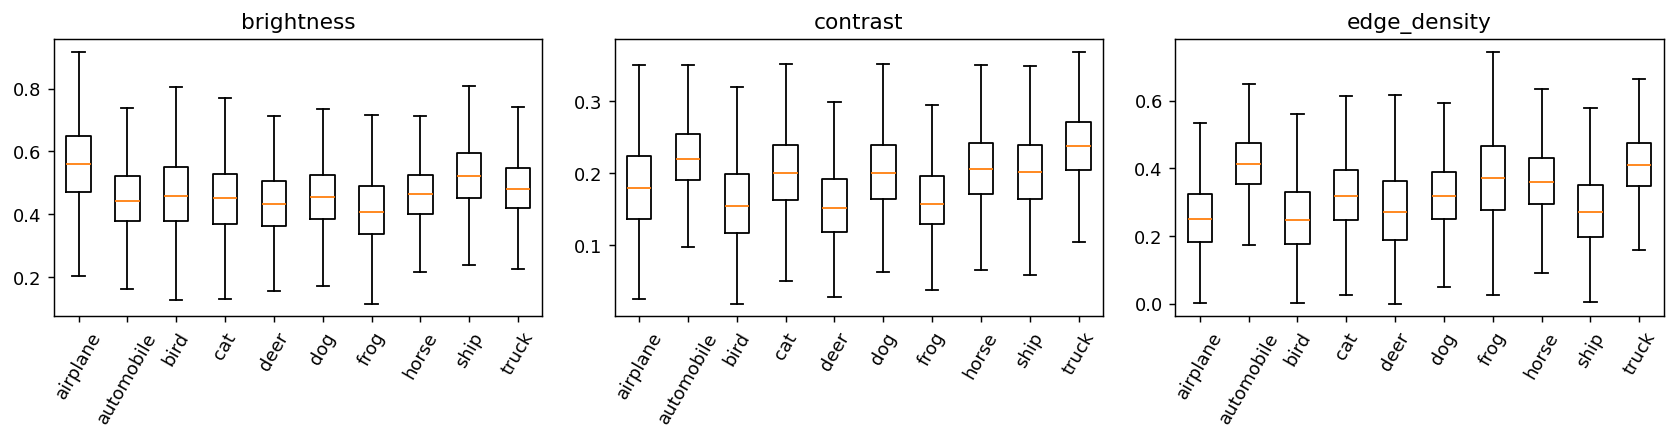

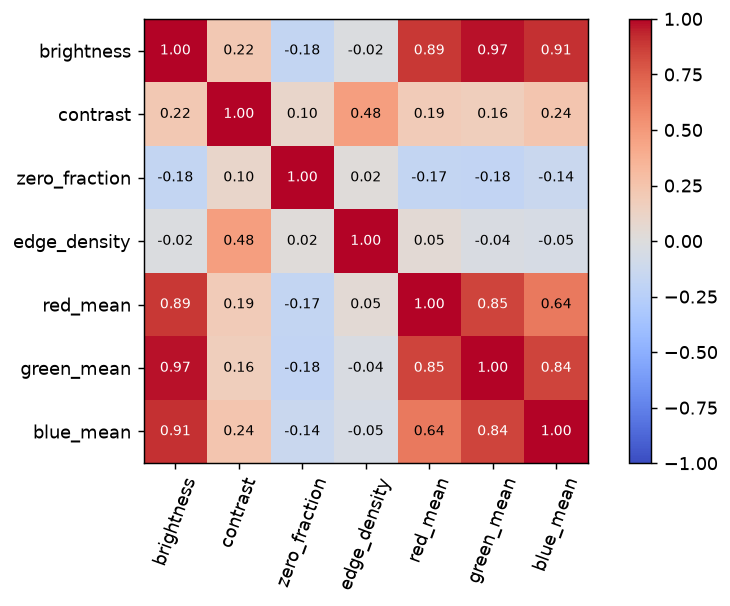

In [7]:
eda.gallery(OUT, 'handcrafted_distributions', 'feature_correlation')

## 6. Tương đồng giữa các lớp

Hàng/cột là 10 lớp CIFAR-10. Mỗi lớp được biểu diễn bằng ảnh RGB trung bình trên train; ảnh được trải phẳng, trừ mean và chuẩn hóa độ dài trước khi tính tương quan giữa các lớp.

- Giá trị so sánh biến thiên RGB ở các vị trí tương ứng của hai ảnh trung bình; không đo mức giống nhau của từng cá thể.
- Ví dụ airplane–ship khoảng 0.80: bố cục màu trung bình có xu hướng tương đồng. Không có nghĩa giống nhau 80% hoặc mô hình nhầm 80%.
- Ma trận ở mục 5 so sánh **đặc trưng qua các ảnh**; ma trận này so sánh **ảnh trung bình giữa các lớp**. Cả hai đều không phải confusion matrix.
- Muốn biết nhầm lớp phải đối chiếu nhãn thật và dự đoán trong notebook Modeling. Các ô hiển thị 2 chữ số thập phân; đường chéo bằng 1.00.

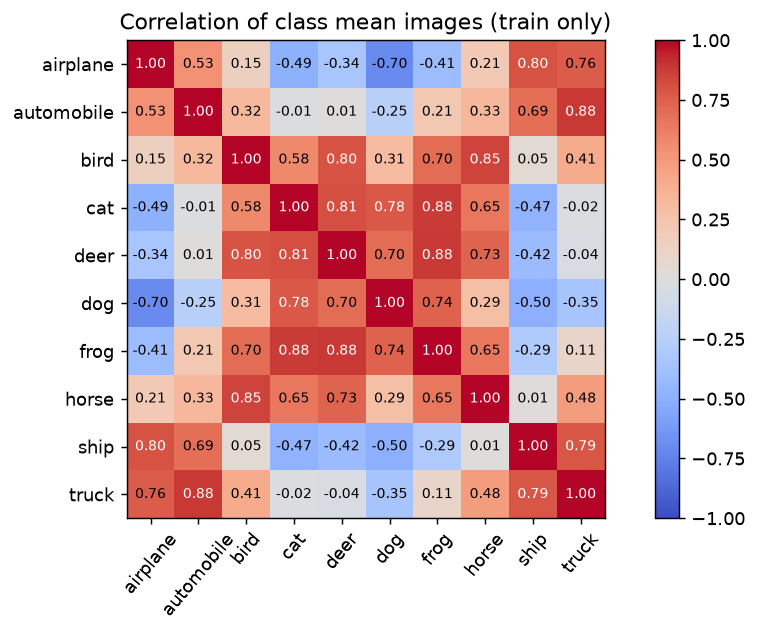

In [8]:
eda.gallery(OUT, 'class_similarity')

## 7. Bàn giao dữ liệu

Artifact tại `outputs/eda/`: split có hash/version, thống kê chỉ trên train và cấu hình tiền xử lý. [Giới hạn và phát hiện](../walkthrough_lab_02.md#13-data-contract-and-partitioning-strategy).

Đã đối chiếu từng mảng index train/val/test: split EDA trùng nội dung và thứ tự với cả `split_indices.npz` và `selected_indices.npz` của run `20261027T135216Z_cifar10_macintel_regularized64_fae6efd8` (45.000/5.000/10.000 ảnh). Hash byte của các file NPZ khác nhau không đồng nghĩa nội dung mảng khác nhau; phép so sánh hash file đơn thuần trước đây báo lỗi. Đây là kết quả đối chiếu cho run này, không bảo đảm mọi run tương lai dùng cùng split.

Modeling nhận ảnh RGB và preprocessing đã chốt; không nhận các đặc trưng thủ công làm đầu vào bổ sung.

In [9]:
eda.handoff(OUT)

,Contract,Value
0,Split,cifar10-stratified-42-45000-5000-v1
1,Preprocessing,rgb-resize64-imagenet-v1
2,Input,float32 CHW: 3 x 64 x 64
3,Normalization,ImageNet constants; measured train RGB statist...
4,Handcrafted features,"Brightness, contrast, RGB means, edge density:..."
5,Foreground / bounding box,not applicable: natural RGB images have no for...


Tái tính từ raw: `python scripts/analyze_data.py --data-dir <thư_mục_data>`. Notebook mặc định xem artifact đã đo; không cần weights hay checkpoint. [Bước tiếp theo](02_lab02_modeling.ipynb).